# Un petit LLM en décision typée (distribution sur options) rivalise-t-il avec CamemBERT fine-tuné sur des intentions françaises hiérarchisées ?

> **En bref.** Le LLM zéro-shot paraît proche de CamemBERT sur le macro-F1, mais il est nettement moins exact et très instable à l'ordre des options. La référence, probablement sous-entraînée, favorise le LLM. macro-F1 : 0,429 [0,398 ; 0,458] pour Décision typée hiérarchique par LLM, contre 0,469 [0,447 ; 0,499] pour CamemBERT-base fine-tuné (1500 exemples de test, échelle complète).

| | |
|---|---|
| **Question** | En zéro-shot hiérarchique avec recalibration, un LLM ≤ 3 Md atteint un macro-F1 à moins de 10 points de CamemBERT-base fine-tuné sur 60 intentions MASSIVE fr, avec une ECE < 0,10 après recalibration et ≥ 95 % de décisions identiques quand l'ordre des options est mélangé. |
| **Référence** | CamemBERT-base fine-tuné — Classifieur plat à 60 classes, encodeur français fine-tuné avec entropie croisée. |
| **Nouvelle approche** | Décision typée hiérarchique par LLM — Le LLM ne génère pas de texte : on lit la distribution de probabilité sur des codes d'options à un caractère, d'abord pour le scénario (18) puis pour l'intention parmi celles du scénario, et on multiplie les probabilités. |
| **Données publiques** | [`mteb/amazon_massive_intent`](https://huggingface.co/datasets/mteb/amazon_massive_intent) (fr) |
| **Métrique principale** | macro-F1 (à maximiser) |

**Sommaire** — 0. Mise en route · 1. La question · 2. Les données · 3. L'approche de référence · 4. La nouvelle approche · 5. Évaluation · 6. Analyse des résultats · 7. Bilan

**Trois façons d'exécuter ce notebook** (cellule de paramètres, section 0) :

| Réglage | À quoi ça sert |
|---|---|
| `PHASE = "public"`, `SCALE = "reduced"` | vérifier que tout fonctionne : quelques minutes sur CPU, sur un échantillon |
| `PHASE = "public"`, `SCALE = "full"` | reproduire les résultats publiés, sur tout le jeu public |
| `PHASE = "private"` | rejouer le même protocole sur vos données, dans votre environnement (voir le README) |

Les sorties affichées sont celles de l'échelle complète (`SCALE = "full"`).

## 0. Mise en route

Trois réglages suffisent : la **phase** (quelles données), l'**échelle** (combien de données et quels modèles) et la **graine** (mêmes tirages, mêmes résultats). Le même code sert aux deux phases : seule la source des données change.

- `PHASE = "public"` charge le jeu public ; `PHASE = "private"` lit vos données d'après `PRIVATE_CONFIG` (cellule suivante) et appelle vos services internes. En phase `private`, aucune donnée brute n'est affichée.
- `SCALE = "reduced"` prend un petit échantillon et, si besoin, des modèles plus petits de la même famille : c'est un test de la mécanique, ses chiffres ne valent pas résultat. `SCALE = "full"` utilise tout le jeu.
- Les fonctions communes (chargement des données internes, appels de services, intervalles de confiance, figures, enregistrement des résultats) sont dans `helpers.py`, à côté du notebook.

Fonctions de `helpers.py` utilisées ici :

| Fonction | Rôle |
|---|---|
| `set_seed` | Graine unique pour random, numpy et torch (s'ils sont présents) : résultats reproductibles. |
| `device` | Matériel de calcul disponible : « cuda » (GPU NVIDIA), « mps » (GPU Apple) ou « cpu ». |
| `sample_size` | Nombre d'exemples à utiliser : `reduced` à l'échelle réduite, `full` (None = tout le jeu) à l'échelle complète. |
| `by_scale` | Valeur qui dépend de l'échelle : modèle substitut, nombre d'époques, de pas ou d'exemples. |
| `service_config` | URL, clé et modèle d'un service à la convention OpenAI : variables <PREFIX>_BASE_URL, _API_KEY, _MODEL. |
| `openai_client` | Client `openai` vers le service <PREFIX>. Proxy et certificats d'entreprise : HTTPS_PROXY, SSL_CERT_FILE ; en-têtes exigés par une passerelle : <PREFIX>_HEADERS (objet JSON). |
| `model_path` | Chemin à passer à `from_pretrained`, dans les deux phases : l'identifiant Hugging Face, ou son dossier local sous LOCAL_MODELS_DIR (org--nom ou org/nom), seul accessible dans un environnement sans Internet. |
| `load_private_data` | Jeu de la phase « private » : DataFrame aux colonnes attendues, lu dans PRIVATE_CONFIG['data'] (ou PRIVATE_DATA), fichier ou dossier (csv, tsv, parquet, jsonl, json, xlsx). |
| `preview` | Premières lignes en phase « public » ; en phase « private », seulement la structure (sauf SHOW_EXAMPLES=1). |
| `fingerprint` | Empreinte courte (sha256) d'un jeu de données, pour la traçabilité des résultats. |
| `timer` | Mesure une durée en millisecondes : `with timer(liste): ...` ajoute la durée à `liste`. |
| `latency_stats` | Médiane (p50) et 95e centile (p95) d'une liste de durées en millisecondes. |
| `bootstrap_ci` | Valeur de `metric(y_true, y_pred)` et son intervalle de confiance à 95 % par bootstrap : (valeur, bas, haut). |
| `save_results` | Valide puis écrit results_<phase>.json dans le dossier des résultats. Structure attendue : |
| `results_table` | Tableau comparatif : une ligne par approche, chaque métrique avec son intervalle de confiance. |
| `save_figure` | Enregistre la figure (figures/<name>.png), l'affiche avec sa légende et la ferme ; ne renvoie rien. |
| `plot_comparison` | Figure de synthèse : une barre par approche et par métrique, avec l'intervalle de confiance à 95 % quand il existe. Par défaut, la métrique principale puis jusqu'à trois autres métriques. Une métrique sans objet pour une approche (None) n'a pas de barre pour elle. |

In [1]:
PHASE = "public"        # "public" : jeu public ; "private" : vos données, dans votre environnement
SCALE = "reduced"       # "reduced" : échantillon, quelques minutes sur CPU ; "full" : tout le jeu
SEED = 42               # graine : mêmes tirages, mêmes résultats
OUTPUT_DIR = "outputs"  # résultats (results_<phase>.json) et figures

### Configuration pour vos données

À modifier seulement pour `PHASE = "private"`. Chaque entrée est expliquée en commentaire ; les valeurs par défaut viennent des variables d'environnement décrites dans `private.env.example`. Au lancement, une liste de contrôle vérifie le jeu, les colonnes, les modèles et les services, et s'arrête sur ce qui manque avant tout calcul.

In [3]:
# Configuration pour vos données (PHASE = "private") : seule cellule à adapter.
# Les valeurs par défaut viennent de l'environnement (modèle : private.env.example).
# Aucune clé ici : elle vient de <SERVICE>_API_KEY, d'un fichier de secret monté (<SERVICE>_API_KEY_FILE) ou d'une saisie masquée.
import os

PRIVATE_CONFIG = {
    # Jeu de données : un fichier (csv, tsv, parquet, jsonl, json, xlsx) ou un dossier de fichiers de même structure.
    "data": os.environ.get("PRIVATE_DATA", ""),
    # Colonne attendue par le notebook -> nom de la colonne dans votre jeu (ne modifier que la partie droite).
    "columns": {'text': 'text', 'reason': 'reason', 'sub_reason': 'sub_reason', 'received_at': 'received_at', 'customer_group': 'customer_group'},
    # Colonnes qui contiennent des chemins de fichiers (relatifs au fichier de données qui les cite, ou absolus).
    "path_columns": [],
    "max_rows": None,                         # plafond facultatif (échantillon aléatoire reproductible)
    "csv": {"sep": None, "encoding": None},   # None : séparateur et encodage devinés (« ; », Windows-1252…)
    # Poids des modèles copiés localement (dossiers org--nom/, script download_models.py), pour travailler sans Internet.
    "models_dir": os.environ.get("LOCAL_MODELS_DIR", ""),
    "models": {'reduced': ['Qwen/Qwen2.5-0.5B-Instruct', 'almanach/camembert-base'], 'full': ['Qwen/Qwen2.5-3B-Instruct', 'almanach/camembert-base']},
    # Autorité de certification d'entreprise (fichier PEM) pour les appels HTTPS internes ; vide sinon.
    "ca_bundle": os.environ.get("SSL_CERT_FILE", ""),
    "llmaas": {"base_url": os.environ.get("LLMAAS_BASE_URL", ""), "model": os.environ.get("LLMAAS_MODEL", ""),
               "api_key_file": os.environ.get("LLMAAS_API_KEY_FILE", ""),
               "headers": {}},  # en-têtes exigés par votre passerelle, s'il y en a
}

### Dépendances et initialisation

Les versions exactes utilisées pour les résultats publiés sont dans `requirements.txt`. Les paquets propres à cette expérience s'installent depuis le notebook avec `INSTALL_DEPENDENCIES=1`.

In [4]:
# Paquets propres à cette expérience (en plus de requirements.txt).
EXTRA_PACKAGES = ['protobuf', 'sentencepiece']
import os, subprocess, sys
if EXTRA_PACKAGES and os.environ.get("INSTALL_DEPENDENCIES") == "1":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *EXTRA_PACKAGES])

In [5]:
from helpers import *  # fonctions communes (voir le tableau ci-dessus)

configure(phase=PHASE, scale=SCALE, seed=SEED, output_dir=OUTPUT_DIR)
apply_private_config(PRIVATE_CONFIG)  # phase private : liste de contrôle, arrêt si quelque chose manque
prepare_environment()                 # télémétrie coupée ; hors ligne si les modèles sont locaux
use_plot_style()
show_configuration()

PHASE=public  SCALE=full  SEED=42  device=cuda  python=3.13.16
service LLM (convention OpenAI)               LLMAAS_BASE_URL=—  LLMAAS_MODEL=—  clé absente
service de transcription (convention OpenAI)  STTAAS_BASE_URL=—  STTAAS_MODEL=—  clé absente
données internes : —  modèles locaux : —


## 1. La question

Pour **router automatiquement des messages** vers un motif, puis vers un sous-motif, deux voies s'offrent à nous :

- **fine-tuner un encodeur français** (CamemBERT) sur des milliers d'exemples étiquetés : c'est la voie classique, fiable mais coûteuse en annotation ;
- **interroger un petit LLM sans aucun entraînement** (zéro-shot) en lisant directement ses probabilités, sans le laisser rédiger de texte.

Un audit indépendant publié en 2026 (*Two Uncertainties Are Not One*) a étudié des modèles de **« décision typée »**. Ces modèles ne génèrent pas de texte : ils renvoient une probabilité ou une distribution sur des options. L'audit les trouve proches des grands LLM pour un coût infime. Il les trouve aussi **surconfiants**, et **battus par un classifieur entraîné** sur les données du domaine. Nous reprenons l'idée en français, sur des intentions organisées en arbre à deux niveaux.

### L'idée de la nouvelle approche

Imaginez un **QCM** : plutôt que de demander au candidat une rédaction, on regarde **à quel point sa main hésite** entre les cases A, B, C… Concrètement :

1. on présente au LLM le message et une liste d'options codées (`A. alarm`, `B. audio`…) ;
2. on lit les scores du modèle pour chaque code au **premier jeton** de sa réponse, puis on les convertit en probabilités (softmax) : c'est la **décision typée** ;
3. on décide d'abord la **catégorie parente** (18 options), puis l'**intention** parmi les enfants de cette parente ;
4. la probabilité finale est le produit $p(\text{intention}) = p(\text{parente}) \times p(\text{intention} \mid \text{parente})$ ;
5. une **recalibration par température**, ajustée sur la validation, corrige la surconfiance relevée par l'audit ;
6. on **mélange l'ordre des options** pour vérifier que la décision ne dépend pas de la position.

### Ce que la comparaison permet de décider

Hypothèse testée : le LLM zéro-shot reste **à moins de 10 points de macro-F1** de CamemBERT fine-tuné, avec une **ECE < 0,10** après recalibration et **≥ 95 % de décisions stables** quand l'ordre des options change. Si c'est le cas, le LLM devient une option crédible pour démarrer sans annotations ou pour couvrir de nouvelles classes. Sinon, le classifieur entraîné reste le bon choix.

## 2. Les données

### Bibliothèques et tailles d'échantillon

On importe les bibliothèques et on fixe les **tailles d'échantillon** avec `sample_size` :
- à l'**échelle réduite**, quelques centaines d'énoncés suffisent à vérifier que tout le code tourne ;
- à l'**échelle complète**, on prend tout l'entraînement, toute la validation et 1 500 énoncés de test.

In [6]:
import gc
import math
import os
import re
import string
from concurrent.futures import ThreadPoolExecutor

import datasets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from scipy.optimize import minimize_scalar
from sklearn.metrics import f1_score

datasets.disable_progress_bars()  # sorties de cellule lisibles

DATASET_ID = "mteb/amazon_massive_intent"  # énoncés d'assistant virtuel, 60 intentions en 18 scénarios
DATASET_CONFIG = "fr"  # partie française du corpus
TRAIN_SIZE = sample_size(reduced=300, full=None)  # énoncés pour fine-tuner CamemBERT (None = tout)
VALIDATION_SIZE = sample_size(reduced=100, full=None)  # énoncés pour ajuster la température
TEST_SIZE = sample_size(reduced=200, full=1500)  # énoncés d'évaluation, communs aux deux approches
set_seed(SEED)

### Outils communs : échantillon et arbre des classes

Les deux phases partagent un **format commun** : `text`, `label` (classe fine), `parent` (catégorie de premier niveau) et `child_name` (nom lisible de la classe fine).

L'**arbre des classes** (parent → enfants) est déduit des données elles-mêmes, sans liste écrite à la main. Le même code sert donc pour le jeu public et pour les données internes.

In [7]:
def take_sample(frame: pd.DataFrame, size: int | None) -> pd.DataFrame:
    """Tire `size` lignes au hasard (graine fixée) ; toutes les lignes si `size` vaut None."""
    if size is None or size >= len(frame):
        return frame.sample(frac=1.0, random_state=SEED).reset_index(drop=True)
    return frame.sample(n=size, random_state=SEED).reset_index(drop=True)


def build_taxonomy(frames: list[pd.DataFrame]) -> dict:
    """Construit l'arbre parent -> classes à partir des données.

    Retour : parents, enfants par parent, liste ordonnée des classes et index associés.
    """
    rows = pd.concat(frames, ignore_index=True)
    pairs = rows[["parent", "label", "child_name"]].drop_duplicates("label")
    parents = sorted(pairs["parent"].unique())
    children = {parent: sorted(pairs.loc[pairs["parent"] == parent, "label"]) for parent in parents}
    # les classes sont rangées parent par parent : un bloc de colonnes par parent
    classes = [label for parent in parents for label in children[parent]]
    return {
        "parents": parents,
        "children": children,
        "classes": classes,
        "class_index": {label: index for index, label in enumerate(classes)},
        "parent_of": dict(zip(pairs["label"], pairs["parent"])),
        "child_name": dict(zip(pairs["label"], pairs["child_name"])),
    }

### Du jeu MASSIVE au format commun

Dans MASSIVE, chaque intention s'écrit `scénario_action` (par exemple `alarm_set`). Le **scénario** (avant le premier `_`) sert de catégorie parente. La suite, rendue lisible (`set`), sert de nom de classe fine. On obtient un arbre à deux niveaux, proche d'un découpage « motif → sous-motif ».

In [8]:
def massive_to_frame(split: datasets.Dataset) -> pd.DataFrame:
    """Convertit une partie de MASSIVE au format commun (text, label, parent, child_name)."""
    raw = split.to_pandas()
    label_column = "label_text" if "label_text" in raw.columns else "label"
    missing = {"text", label_column} - set(raw.columns)
    if missing:
        raise ValueError(f"Colonnes manquantes dans le jeu public : {sorted(missing)}")
    frame = pd.DataFrame({"text": raw["text"].astype(str), "label": raw[label_column].astype(str)})
    parts = frame["label"].str.split("_", n=1)
    frame["parent"] = parts.str[0]
    # nom lisible de l'action ; repli sur l'étiquette entière si elle n'a pas de « _ »
    frame["child_name"] = parts.str[1].fillna(frame["label"]).str.replace("_", " ")
    return frame

### Chargement du jeu public

On télécharge les trois parties officielles (train, validation, test). L'**arbre complet** est construit **avant** l'échantillonnage : le LLM doit voir les 60 intentions comme options, même à l'échelle réduite, où certaines classes manquent dans l'échantillon.

In [9]:
if PHASE == "public":
    massive = datasets.load_dataset(DATASET_ID, DATASET_CONFIG)
    full_frames = {name: massive_to_frame(massive[name]) for name in ("train", "validation", "test")}
    taxonomy = build_taxonomy(list(full_frames.values()))
    train_df = take_sample(full_frames["train"], TRAIN_SIZE)
    validation_df = take_sample(full_frames["validation"], VALIDATION_SIZE)
    test_df = take_sample(full_frames["test"], TEST_SIZE)
    DATASET_INFO = {"name": DATASET_ID, "config": DATASET_CONFIG, "split": "test"}
    print(f"{len(taxonomy['classes'])} intentions réparties en {len(taxonomy['parents'])} scénarios")

README.md:   0%|          | 0.00/29.5k [00:00<?, ?B/s]

train/fr.json.gz: reconstructing file:   0%|          |  0.00B /  211kB            

train/fr.json.gz: downloading bytes:           |  0.00B            

test/fr.json.gz: reconstructing file:   0%|          |  0.00B / 60.4kB            

test/fr.json.gz: downloading bytes:           |  0.00B            

validation/fr.json.gz: reconstructing file:   0%|          |  0.00B / 42.5kB            

validation/fr.json.gz: downloading bytes:           |  0.00B            

60 intentions réparties en 18 scénarios


### Contrôles et vue d'ensemble

Deux fonctions réutilisées dans les deux phases :
- `split_summary` : effectifs, nombre de classes présentes, plus petit effectif par classe et longueur des textes en mots ;
- `plot_data_overview` : une figure avec le nombre d'exemples d'entraînement par catégorie parente et la distribution des longueurs dans le test.

In [10]:
def split_summary(frames: dict[str, pd.DataFrame]) -> pd.DataFrame:
    """Effectifs, classes présentes et longueur des textes (en mots) pour chaque partie."""
    rows = []
    for name, frame in frames.items():
        words = frame["text"].str.split().str.len()
        counts = frame["label"].value_counts()
        rows.append({"partie": name, "exemples": len(frame), "classes présentes": frame["label"].nunique(),
                     "exemples / classe (min)": int(counts.min()), "mots (médiane)": float(words.median()),
                     "mots (max)": int(words.max())})
    return pd.DataFrame(rows).set_index("partie")


def plot_data_overview(train: pd.DataFrame, test: pd.DataFrame) -> None:
    """Figure : exemples d'entraînement par catégorie parente et longueur des textes de test."""
    fig, (left, right) = plt.subplots(1, 2, figsize=(12, 5))
    per_parent = train["parent"].value_counts().sort_values()
    left.barh(per_parent.index, per_parent.values, color=COLORS["accent"])
    left.set(title="Entraînement : exemples par catégorie parente",
             xlabel="Nombre d'exemples", ylabel="Catégorie parente")
    right.hist(test["text"].str.split().str.len(), bins=20, color=COLORS["reference"])
    right.set(title="Test : longueur des textes", xlabel="Longueur (mots)", ylabel="Nombre de textes")
    fig.tight_layout()
    save_figure(fig, "data_overview",
                "À gauche, le nombre d'exemples d'entraînement par catégorie parente : une barre courte signale "
                "une catégorie peu représentée. À droite, la longueur des textes de test en mots : des textes "
                "courts laissent peu d'indices aux deux approches.")

### Ce que contiennent les données publiques

On affiche le tableau de contrôle, la figure, puis quelques énoncés de test avec leur catégorie parente et leur intention.

,exemples,classes présentes,exemples / classe (min),mots (médiane),mots (max)
partie,,,,,
train,11514,60,4,7.0,37
validation,2033,59,2,7.0,29
test,1500,59,1,7.0,76


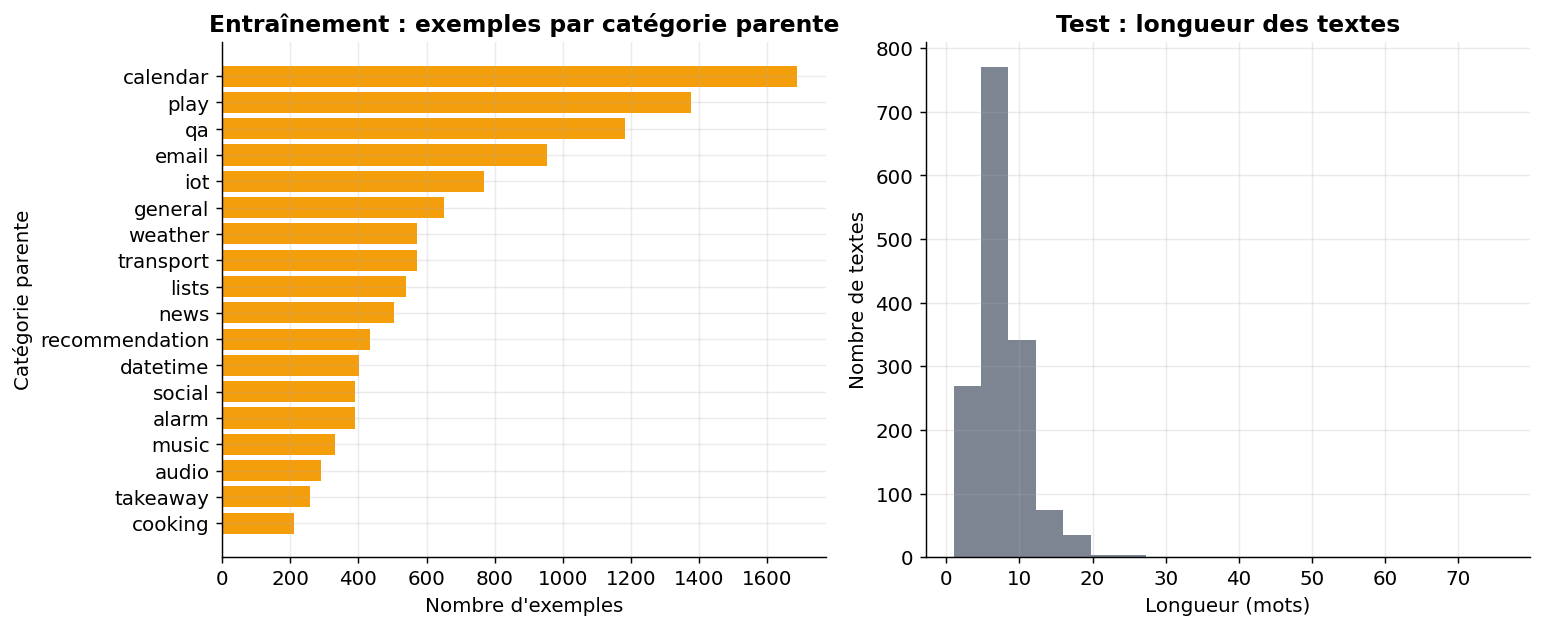

*Figure — À gauche, le nombre d'exemples d'entraînement par catégorie parente : une barre courte signale une catégorie peu représentée. À droite, la longueur des textes de test en mots : des textes courts laissent peu d'indices aux deux approches.*

In [11]:
if PHASE == "public":
    display(split_summary({"train": train_df, "validation": validation_df, "test": test_df}))
    plot_data_overview(train_df, test_df)
    preview(test_df[["text", "parent", "label"]], n=5)

### Colonnes attendues et gabarits du jeu factice

Les données internes doivent fournir les colonnes ci-dessous. Pour vérifier le code sans données réelles, on fabrique un **jeu factice**. Il contient des messages inventés sur une carte de paiement, un compte ou un virement, et ne comporte **aucune donnée réelle**. Les gabarits ci-dessous sont groupés par motif puis par sous-motif.

In [12]:
PRIVATE_COLUMNS = {
    "text": "Texte du message ou e-mail (anonymisé)",
    "reason": "Motif de premier niveau",
    "sub_reason": "Sous-motif",
    "received_at": "Date de réception",
    "customer_group": "Identifiant pseudonymisé pour découpage par client",
}
FAKE_TAXONOMY = {  # motif -> sous-motif -> gabarits de messages inventés
    "carte de paiement": {
        "carte bloquée": ["ma carte de paiement est bloquée depuis le {jour}.", "paiement refusé, ma carte semble bloquée."],
        "plafond de paiement": ["je voudrais relever mon plafond à {montant} euros.", "mon plafond de paiement est atteint, que faire ?"],
        "carte non reçue": ["je n'ai pas reçu la carte demandée le {jour}.", "toujours aucune nouvelle carte de paiement dans ma boîte."]},
    "compte": {
        "relevé de compte": ["je ne trouve pas mon relevé de compte de {mois}.", "pouvez-vous m'envoyer le relevé de {mois} ?"],
        "changement d'adresse": ["je déménage le {jour}, merci de mettre à jour mon adresse.", "nouvelle adresse postale à enregistrer sur mon compte."],
        "clôture du compte": ["je souhaite clôturer mon compte avant le {jour}.", "comment fermer définitivement mon compte ?"]},
    "virement": {
        "virement non reçu": ["le virement de {montant} euros du {jour} n'est pas arrivé.", "mon destinataire n'a pas reçu les {montant} euros."],
        "ajout de bénéficiaire": ["comment ajouter un bénéficiaire pour mes virements ?", "impossible d'enregistrer un nouveau bénéficiaire."],
        "virement à l'étranger": ["quels frais pour un virement de {montant} euros vers l'étranger ?", "délai d'un virement international de {montant} euros ?"]},
    "accès en ligne": {
        "mot de passe oublié": ["j'ai oublié mon mot de passe de l'espace en ligne.", "mon code d'accès ne marche plus depuis le {jour}."],
        "application inaccessible": ["l'application affiche une erreur depuis le {jour}.", "l'application mobile se ferme dès la connexion."]},
    "réclamation": {
        "frais contestés": ["je conteste les frais de {montant} euros de ce mois-ci.", "des frais de {montant} euros apparaissent sans explication."],
        "délai de traitement": ["ma demande du {jour} n'est toujours pas traitée.", "trois semaines d'attente sans réponse, c'est long."]},
    "documents": {
        "attestation demandée": ["pouvez-vous me fournir une attestation de compte ?", "il me faut une attestation avant le {jour}."],
        "copie de contrat": ["je souhaite une copie de mon contrat de carte de paiement.", "où trouver la copie du contrat signé le {jour} ?"]},
}
OPENERS = ["", "Bonjour, ", "Bonjour Madame, Monsieur, ", "Bonsoir, "]  # formules d'ouverture variées
CLOSERS = ["", " Merci d'avance.", " Cordialement.", " Merci de votre retour rapide."]  # formules de fin
FAKE_MONTHS = ["janvier", "février", "mars", "avril", "mai", "juin", "juillet", "août"]

### Fabrication du jeu factice

`make_fake_data(n)` tire, pour chaque ligne, un sous-motif (classes équilibrées), un gabarit, des montants et des dates au hasard. Elle ajoute une date de réception étalée sur environ 8 mois et un identifiant de groupe pseudonymisé. Les lignes sont ensuite mélangées : le code ne doit dépendre ni de leur ordre ni des étiquettes du jeu public.

In [13]:
def make_fake_data(n: int) -> pd.DataFrame:
    """Jeu factice plausible aux colonnes de PRIVATE_COLUMNS, sans aucune donnée réelle."""
    rng = np.random.default_rng(SEED)
    pairs = [(reason, sub) for reason, subs in FAKE_TAXONOMY.items() for sub in subs]
    start = pd.Timestamp("2025-01-01")
    rows = []
    for row in range(n):
        reason, sub_reason = pairs[row % len(pairs)]  # même effectif pour chaque sous-motif
        template = str(rng.choice(FAKE_TAXONOMY[reason][sub_reason]))
        body = template.format(jour=f"{rng.integers(1, 29)} {rng.choice(FAKE_MONTHS)}",
                               montant=int(rng.integers(20, 3000)), mois=rng.choice(FAKE_MONTHS))
        received = start + pd.Timedelta(seconds=int(rng.integers(0, 240 * 86400)))
        rows.append({
            "text": f"{rng.choice(OPENERS)}{body}{rng.choice(CLOSERS)}".strip(),
            "reason": reason,
            "sub_reason": sub_reason,
            "received_at": received.strftime("%Y-%m-%d %H:%M:%S"),
            "customer_group": f"grp_{int(rng.integers(0, 5000)):05d}",
        })
    return pd.DataFrame(rows).sample(frac=1.0, random_state=SEED).reset_index(drop=True)

### Types, nettoyage et découpage sans fuite

Le jeu est relu depuis un fichier : on **convertit explicitement chaque type**. On écarte les messages sans motif validé ou sans date, puis on retire les doublons. La classe fine devient `motif › sous-motif`, car un même sous-motif peut exister sous deux motifs.

Le découpage évite deux **fuites** :
- **temporelle** : les messages les plus récents servent au test, ceux qui les précèdent à la validation ;
- **par client** : un groupe présent dans le test n'apparaît ni en validation ni en entraînement.

In [14]:
TEST_FRACTION = 0.2  # part la plus récente réservée à l'évaluation
VALIDATION_FRACTION = 0.15  # part précédente, pour ajuster la température


def prepare_private_frame(raw: pd.DataFrame) -> pd.DataFrame:
    """Types explicites, motifs validés seulement, format commun (text, label, parent, child_name)."""
    missing = set(PRIVATE_COLUMNS) - set(raw.columns)
    if missing:
        raise ValueError(f"Colonnes manquantes : {sorted(missing)}")
    frame = pd.DataFrame({
        "text": raw["text"].astype(str).str.strip(),
        "parent": raw["reason"].astype(str).str.strip(),
        "child_name": raw["sub_reason"].astype(str).str.strip(),
        "received_at": pd.to_datetime(raw["received_at"], errors="coerce", utc=True),
        "customer_group": raw["customer_group"].astype(str).str.strip(),
    })
    empty = {"", "nan", "None", "NaT"}
    keep = (~frame[["text", "parent", "child_name"]].isin(empty).any(axis=1)) & frame["received_at"].notna()
    print(f"Lignes écartées (texte, motif ou date manquants) : {int((~keep).sum())}")
    frame = frame[keep].copy()
    frame["label"] = frame["parent"] + " › " + frame["child_name"]
    return frame.drop_duplicates(["text", "label"]).reset_index(drop=True)


def temporal_customer_split(frame: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Découpe par date (test = plus récent) puis retire de l'apprentissage les groupes vus en test."""
    frame = frame.sort_values(["received_at", "text"]).reset_index(drop=True)  # tri indépendant du fichier
    test_start = int(len(frame) * (1 - TEST_FRACTION))
    validation_start = int(len(frame) * (1 - TEST_FRACTION - VALIDATION_FRACTION))
    test = frame.iloc[test_start:]
    validation = frame.iloc[validation_start:test_start]
    validation = validation[~validation["customer_group"].isin(set(test["customer_group"]))]
    seen_later = set(test["customer_group"]) | set(validation["customer_group"])
    train = frame.iloc[:validation_start]
    train = train[~train["customer_group"].isin(seen_later)]
    return train, validation, test

### Chargement des données internes

`load_private_data` lit le jeu indiqué par la configuration, ou fabrique le jeu factice. Ensuite viennent exactement les mêmes étapes qu'en phase publique : arbre des classes, échantillons, tableau de contrôle et figure. Seule la **structure** des exemples est montrée, jamais leur contenu.

In [15]:
if PHASE == "private":
    private_raw = load_private_data(PRIVATE_COLUMNS, make_fake_data, n_fake=600)
    private_frame = prepare_private_frame(private_raw)
    taxonomy = build_taxonomy([private_frame])  # arbre déduit des données, avant échantillonnage
    train_part, validation_part, test_part = temporal_customer_split(private_frame)
    train_df = take_sample(train_part, TRAIN_SIZE)
    validation_df = take_sample(validation_part, VALIDATION_SIZE)
    test_df = take_sample(test_part, TEST_SIZE)
    DATASET_INFO = {"name": "données internes", "config": "motif › sous-motif",
                    "split": "test (période la plus récente)"}
    print(f"{len(taxonomy['classes'])} sous-motifs répartis en {len(taxonomy['parents'])} motifs")
    display(split_summary({"train": train_df, "validation": validation_df, "test": test_df}))
    plot_data_overview(train_df, test_df)
    preview(test_df[["text", "parent", "label"]])

## 3. L'approche de référence

### Principe et réglages de la référence

**CamemBERT-base** est un encodeur français de 110 M de paramètres. On lui ajoute une **tête de classification** sur toutes les classes fines, puis on le **fine-tune** par entropie croisée : ses poids s'ajustent sur les exemples étiquetés.

Les réglages suivent les pratiques courantes : taux d'apprentissage 3e-5 avec montée progressive (*warmup*), puis décroissance linéaire. Les énoncés sont tronqués à 64 jetons. On fait 3 époques à l'échelle complète et 1 à l'échelle réduite.

In [16]:
from transformers import (AutoModelForCausalLM, AutoModelForSequenceClassification, AutoTokenizer,
                          get_linear_schedule_with_warmup)
from transformers.utils import logging as transformers_logging

transformers_logging.set_verbosity_error()  # masque l'avertissement attendu sur la tête neuve
transformers_logging.disable_progress_bar()

REFERENCE_ID = "almanach/camembert-base"  # encodeur français de 110 M de paramètres
EPOCHS = by_scale(reduced=1, full=3)  # passes complètes sur l'entraînement
LEARNING_RATE = 3e-5  # taux classique pour un fine-tuning d'encodeur
BATCH_SIZE = by_scale(reduced=16, full=32)  # exemples par pas de gradient
MAX_LENGTH = 64  # jetons au plus : les messages visés sont courts
WARMUP_RATIO = 0.1  # 10 % des pas en montée progressive du taux
WEIGHT_DECAY = 0.01  # régularisation légère des poids
LATENCY_SIZE = sample_size(reduced=20, full=100)  # textes chronométrés un par un

COMPUTE_DEVICE = device()
classes = taxonomy["classes"]
latency_texts = test_df["text"].tolist()[:LATENCY_SIZE]
print(f"Calcul sur : {COMPUTE_DEVICE} — {len(classes)} classes, {len(taxonomy['parents'])} catégories parentes")
print(f"Empreinte du jeu de test : {fingerprint(test_df[['text', 'label']])}")

Calcul sur : cuda — 60 classes, 18 catégories parentes
Empreinte du jeu de test : 8ee34db05d970d1d


### Outils de probabilité partagés

Les deux approches produisent des **scores bruts** (*logits*). La **softmax à température** les convertit en probabilités :

$$p_k = \frac{e^{z_k/T}}{\sum_j e^{z_j/T}}$$

Avec $T > 1$, les probabilités sont adoucies (moins de surconfiance). Avec $T < 1$, elles sont accentuées. On choisit $T$ en minimisant la **log-vraisemblance négative** sur la validation, jamais sur le test. Comme $T$ ne change pas l'ordre des scores, les décisions restent identiques.

In [17]:
PARENT_MEMBERS = [[taxonomy["class_index"][label] for label in taxonomy["children"][parent]]
                  for parent in taxonomy["parents"]]  # colonnes de chaque parent dans la matrice de probabilités


def softmax(logits: np.ndarray, temperature: float = 1.0) -> np.ndarray:
    """Softmax à température sur le dernier axe."""
    scaled = np.asarray(logits, dtype=float) / temperature
    scaled = scaled - scaled.max(axis=-1, keepdims=True)  # stabilité numérique
    exps = np.exp(scaled)
    return exps / exps.sum(axis=-1, keepdims=True)


def negative_log_likelihood(probs: np.ndarray, labels) -> float:
    """Log-vraisemblance négative moyenne de la vraie classe."""
    indices = [taxonomy["class_index"][label] for label in labels]
    true_probs = probs[np.arange(len(indices)), indices]
    return float(-np.mean(np.log(np.clip(true_probs, 1e-12, None))))


def fit_temperature(loss_of_temperature) -> float:
    """Température qui minimise `loss_of_temperature(T)`, cherchée entre e^-3 et e^3."""
    result = minimize_scalar(lambda log_t: loss_of_temperature(float(np.exp(log_t))),
                             bounds=(-3.0, 3.0), method="bounded")
    return float(np.exp(result.x))

### Chargement de CamemBERT

Le modèle est chargé par `model_path`, qui pointe vers le Hub en phase publique et vers une copie locale dans l'environnement cible. La graine est fixée juste avant, car la tête de classification est initialisée au hasard.

In [18]:
set_seed(SEED)
reference_tokenizer = AutoTokenizer.from_pretrained(model_path(REFERENCE_ID))
reference_model = AutoModelForSequenceClassification.from_pretrained(
    model_path(REFERENCE_ID),
    num_labels=len(classes),
    id2label=dict(enumerate(classes)),
    label2id=taxonomy["class_index"],
).to(COMPUTE_DEVICE)
print(f"{sum(p.numel() for p in reference_model.parameters()) / 1e6:.0f} M de paramètres")

111 M de paramètres


### Boucle de fine-tuning

Une boucle PyTorch explicite, pour garder la main sur chaque réglage :
- lots tirés dans un ordre **reproductible** (générateur à graine) ;
- **précision mixte** (`float16`) seulement sur GPU, pour aller plus vite sans changer le résultat attendu ;
- **écrêtage du gradient** à 1, qui évite les pas trop brusques au début.

In [19]:
def train_reference(model, texts: list[str], labels: list[str]) -> list[float]:
    """Fine-tune l'encodeur par entropie croisée ; rend la perte moyenne de chaque époque."""
    targets = torch.tensor([taxonomy["class_index"][label] for label in labels])
    generator = torch.Generator().manual_seed(SEED)  # ordre des lots reproductible
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    total_steps = EPOCHS * math.ceil(len(texts) / BATCH_SIZE)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_RATIO * total_steps), total_steps)
    use_amp = COMPUTE_DEVICE == "cuda"  # précision mixte seulement sur GPU
    amp_device = "cuda" if use_amp else "cpu"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    model.train()
    epoch_losses = []
    for _ in range(EPOCHS):
        order = torch.randperm(len(texts), generator=generator).tolist()
        losses = []
        for start in range(0, len(order), BATCH_SIZE):
            batch = order[start:start + BATCH_SIZE]
            encoded = reference_tokenizer([texts[i] for i in batch], padding=True, truncation=True,
                                          max_length=MAX_LENGTH, return_tensors="pt").to(COMPUTE_DEVICE)
            with torch.autocast(device_type=amp_device, dtype=torch.float16, enabled=use_amp):
                loss = model(**encoded, labels=targets[batch].to(COMPUTE_DEVICE)).loss
            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            losses.append(loss.item())
        epoch_losses.append(float(np.mean(losses)))
    model.eval()
    return epoch_losses

### Entraînement

On lance le fine-tuning et on affiche la **perte moyenne par époque**. Elle doit baisser d'une époque à l'autre. À l'échelle réduite (une seule époque sur quelques centaines d'exemples), elle reste haute : la référence y est volontairement sous-entraînée, et ces chiffres servent seulement à valider le code.

In [20]:
training_ms: list[float] = []
with timer(training_ms):
    epoch_losses = train_reference(reference_model, train_df["text"].tolist(), train_df["label"].tolist())
loss_table = pd.DataFrame({"époque": range(1, len(epoch_losses) + 1), "perte moyenne": np.round(epoch_losses, 3)})
display(loss_table.set_index("époque"))
print(f"Durée d'entraînement : {training_ms[0] / 1000:.0f} s sur {len(train_df)} textes")

,perte moyenne
époque,
1,3.468
2,2.252
3,1.792


Durée d'entraînement : 98 s sur 11514 textes


### Prédiction, décision par niveau et latence

- `reference_logits` calcule les scores par lots.
- `flat_decisions` prend la classe fine la plus probable. Pour la catégorie parente, il **additionne les probabilités des enfants** de chaque parent. La parente et l'intention peuvent alors se contredire : c'est ce que mesure la **cohérence parent-enfant**.
- La **latence** est mesurée un texte à la fois, comme pour un message isolé.

In [21]:
@torch.no_grad()
def reference_logits(texts: list[str], batch_size: int = 64) -> np.ndarray:
    """Scores bruts de CamemBERT pour chaque texte (matrice textes × classes)."""
    chunks = []
    for start in range(0, len(texts), batch_size):
        encoded = reference_tokenizer(texts[start:start + batch_size], padding=True, truncation=True,
                                      max_length=MAX_LENGTH, return_tensors="pt").to(COMPUTE_DEVICE)
        chunks.append(reference_model(**encoded).logits.float().cpu().numpy())
    return np.concatenate(chunks)


def flat_decisions(probs: np.ndarray) -> dict:
    """Classe fine la plus probable, parente par somme des probabilités, et leur cohérence."""
    pred_labels = np.array([classes[index] for index in probs.argmax(axis=1)], dtype=object)
    parent_probs = np.stack([probs[:, members].sum(axis=1) for members in PARENT_MEMBERS], axis=1)
    pred_parents = np.array([taxonomy["parents"][index] for index in parent_probs.argmax(axis=1)], dtype=object)
    consistency = np.array([taxonomy["parent_of"][label] == parent
                            for label, parent in zip(pred_labels, pred_parents)])
    return {"pred_labels": pred_labels, "pred_parents": pred_parents, "consistency": consistency}

### Exécution de la référence

Dans l'ordre : scores sur la validation, **ajustement de la température**, scores sur le test, puis chronométrage. Le résultat est rangé dans `reference_outputs`, au même format que la nouvelle approche :
- probabilités brutes et recalibrées ;
- décisions par niveau ;
- latences.

In [22]:
validation_logits = reference_logits(validation_df["text"].tolist())
reference_temperature = fit_temperature(
    lambda t: negative_log_likelihood(softmax(validation_logits, t), validation_df["label"]))
test_logits = reference_logits(test_df["text"].tolist())

reference_latencies: list[float] = []
for text in latency_texts:  # un texte à la fois : latence vue par un message isolé
    with timer(reference_latencies):
        reference_logits([text])

reference_outputs = {
    "probs_raw": softmax(test_logits),
    "probs": softmax(test_logits, reference_temperature),
    **flat_decisions(softmax(test_logits)),
    "latencies": reference_latencies,
    "invalid_rate": 0.0,
}
print(f"Température ajustée sur la validation : {reference_temperature:.2f}")

Température ajustée sur la validation : 0.47


### Libération de la mémoire

Avant de charger le LLM, on libère CamemBERT. Sur GPU, c'est indispensable pour tenir dans 16 Go.

In [23]:
del reference_model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

## 4. La nouvelle approche

### Principe et fidélité à la source

L'approche reprend le cœur du modèle « System One » audité (section *comment ça marche* de l'audit). Le modèle **ne rédige pas** : on lit une **décision typée**, ici une distribution sur des options codées, au premier jeton de la réponse.

**Écarts assumés** avec l'audit :
- un LLM ouvert de la famille Qwen2.5 remplace le produit commercial anonymisé ;
- la question est un **choix parmi des options** à deux niveaux, au lieu de dix questions oui/non ;
- on n'utilise pas la « dispersion de décomposition » sur des sous-attributs ;
- une **recalibration par température** (une seule $T$ pour les deux niveaux) remplace la recalibration isotonique de l'audit ;
- en phase publique, le LLM tourne en local ; dans l'environnement cible, il est appelé via le service interne.

In [24]:
LLM_ID = by_scale(reduced="Qwen/Qwen2.5-0.5B-Instruct", full="Qwen/Qwen2.5-3B-Instruct")  # LLM local
OPTION_CODES = list(string.ascii_uppercase + string.ascii_lowercase + string.digits)  # 62 codes d'un caractère
LLM_BATCH_SIZE = by_scale(reduced=8, full=16)  # prompts traités ensemble en local
N_PERMUTATIONS = 3  # ordres mélangés pour le test de stabilité
PERMUTATION_SIZE = sample_size(reduced=40, full=300)  # textes de test soumis aux permutations
SERVICE_WORKERS = 8  # appels simultanés au service (phase private)
MISSING_LOGPROB = -30.0  # log-probabilité attribuée à un code absent de la réponse du service
INVALID = "__sortie_illisible__"  # décision d'une sortie illisible : toujours comptée comme erreur
SYSTEM_PROMPT = ("Tu es un système de routage de messages. "
                 "Tu réponds uniquement par le code d'une option, sans aucun autre texte.")
PARENT_QUESTION = "Quelle catégorie générale correspond le mieux à ce message ?"
CHILD_QUESTION = "Quelle intention précise correspond le mieux à ce message ?"

too_many = {parent: len(labels) for parent, labels in taxonomy["children"].items()
            if len(labels) > len(OPTION_CODES)}
if len(taxonomy["parents"]) > len(OPTION_CODES) or too_many:
    raise ValueError(f"Plus de {len(OPTION_CODES)} options à un niveau : {too_many or 'catégories parentes'}")

### Le prompt à options codées

Chaque option reçoit un **code d'un caractère** (`A`, `B`…). Le modèle n'a alors qu'un seul jeton à « choisir ». On affiche un prompt construit sur un texte d'exemple neutre, pour voir exactement ce que lit le modèle.

In [25]:
def readable(name: str) -> str:
    """Nom d'option lisible (tirets bas remplacés par des espaces)."""
    return name.replace("_", " ")


def build_messages(text: str, option_names: list[str], question: str) -> list[dict]:
    """Messages de chat : consigne système, puis message, question et options codées."""
    lines = [f"{code}. {name}" for code, name in zip(OPTION_CODES, option_names)]
    user = (f"Message : « {text} »\n\n{question}\nOptions :\n" + "\n".join(lines)
            + "\n\nRéponds uniquement par le code de l'option.")
    return [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": user}]


example_options = [readable(parent) for parent in taxonomy["parents"][:4]]
print(build_messages("exemple de message", example_options, PARENT_QUESTION)[1]["content"])

Message : « exemple de message »

Quelle catégorie générale correspond le mieux à ce message ?
Options :
A. alarm
B. audio
C. calendar
D. cooking

Réponds uniquement par le code de l'option.


### Chargement du LLM local (phase publique)

On charge le LLM en `float16` sur GPU et en `float32` sur CPU. On vérifie que **chaque code est un seul jeton**.

Astuce d'efficacité : on garde seulement les **lignes de la couche de sortie** qui correspondent aux 62 codes. On évite ainsi de calculer des scores pour les quelque 150 000 jetons du vocabulaire.

In [26]:
if PHASE == "public":
    llm_dtype = torch.float16 if COMPUTE_DEVICE == "cuda" else torch.float32
    llm_tokenizer = AutoTokenizer.from_pretrained(model_path(LLM_ID))
    llm_tokenizer.padding_side = "left"  # le dernier jeton de chaque prompt est aligné à droite
    if llm_tokenizer.pad_token is None:
        llm_tokenizer.pad_token = llm_tokenizer.eos_token
    llm_model = AutoModelForCausalLM.from_pretrained(model_path(LLM_ID), torch_dtype=llm_dtype)
    llm_model = llm_model.to(COMPUTE_DEVICE).eval()
    code_token_ids = [llm_tokenizer.encode(code, add_special_tokens=False) for code in OPTION_CODES]
    if any(len(ids) != 1 for ids in code_token_ids):
        raise ValueError("Chaque code d'option doit correspondre à un seul jeton.")
    output_weights = llm_model.get_output_embeddings().weight
    code_weights = output_weights[[ids[0] for ids in code_token_ids]].detach().float()
    print(f"{LLM_ID} : {sum(p.numel() for p in llm_model.parameters()) / 1e9:.2f} Md de paramètres")

Qwen/Qwen2.5-3B-Instruct : 3.09 Md de paramètres


### Scores des codes en local

Les prompts d'un lot sont complétés à gauche (*padding*). On recalcule alors les **positions** des jetons à partir du masque d'attention : sans cela, un prompt court serait lu comme s'il commençait plus loin. On garde l'état caché du **dernier jeton** et on le multiplie par les poids des codes.

In [27]:
@torch.no_grad()
def local_option_logits(messages_batch: list[list[dict]], n_options_batch: list[int]) -> list[np.ndarray]:
    """Scores des codes d'options au premier jeton de réponse, pour un lot de prompts."""
    prompts = [llm_tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
               for messages in messages_batch]
    encoded = llm_tokenizer(prompts, return_tensors="pt", padding=True, add_special_tokens=False)
    encoded = encoded.to(COMPUTE_DEVICE)
    position_ids = (encoded["attention_mask"].cumsum(-1) - 1).clamp(min=0)  # positions vraies malgré le padding
    hidden = llm_model.model(input_ids=encoded["input_ids"], attention_mask=encoded["attention_mask"],
                             position_ids=position_ids).last_hidden_state[:, -1, :]
    code_logits = (hidden.float() @ code_weights.T).cpu().numpy()
    return [row[:n_options] for row, n_options in zip(code_logits, n_options_batch)]

### Scores des codes via le service interne (phase private)

Dans l'environnement cible, le LLM est un service à la convention OpenAI. URL, clé et modèle viennent de l'environnement. On demande **un seul jeton** avec ses **log-probabilités** (les 20 plus probables).

Si le service refuse les log-probabilités, on se replie sur la **réponse écrite** : le code choisi reçoit toute la probabilité. Un appel en échec est retenté au plus une fois.

In [28]:
SERVICE_STATE = {"logprobs": True}  # passe à False si le service refuse les log-probabilités


def service_model_name() -> str:
    """Nom du modèle du service, lu dans la configuration de l'environnement."""
    config = service_config("LLMAAS")
    if isinstance(config, dict):
        model = config.get("model")
    elif isinstance(config, (tuple, list)) and len(config) >= 3:
        model = config[2]
    else:
        model = getattr(config, "model", None)
    return model or os.environ.get("LLMAAS_MODEL", "")


def call_service(messages: list[dict]):
    """Un appel au service : avec log-probabilités si possible, sinon texte seul ; None en cas d'échec."""
    for _ in range(2):  # au plus deux tentatives
        use_logprobs = SERVICE_STATE["logprobs"]
        options = {"logprobs": True, "top_logprobs": 20, "max_tokens": 1} if use_logprobs else {"max_tokens": 5}
        try:
            return SERVICE_CLIENT.chat.completions.create(
                model=SERVICE_MODEL, messages=messages, temperature=0.0, **options)
        except Exception:
            if not use_logprobs:
                return None
            SERVICE_STATE["logprobs"] = False  # nouvelle tentative sans log-probabilités
    return None


if PHASE == "private":
    SERVICE_CLIENT = openai_client("LLMAAS")
    SERVICE_MODEL = service_model_name()

### Lecture de la réponse du service

On rapporte chaque log-probabilité de jeton au code correspondant. Un code absent reçoit une valeur très basse. Si **aucun code** n'est reconnu, la sortie est **illisible** : scores uniformes, drapeau `False`. La décision sera ensuite comptée comme une erreur.

In [29]:
def service_option_logits(messages: list[dict], n_options: int) -> tuple[np.ndarray, bool]:
    """Scores des codes lus dans la réponse du service, et drapeau de lisibilité."""
    codes = OPTION_CODES[:n_options]
    response = call_service(messages)
    if response is None or not response.choices:
        return np.zeros(n_options), False
    choice = response.choices[0]
    logits = np.full(n_options, MISSING_LOGPROB)
    token_logprobs = getattr(choice.logprobs, "content", None) if choice.logprobs else None
    if token_logprobs and token_logprobs[0].top_logprobs:
        for candidate in token_logprobs[0].top_logprobs:
            token = candidate.token.strip()
            if token in codes:
                index = codes.index(token)
                logits[index] = max(logits[index], candidate.logprob)
    else:
        match = re.search(r"\b([A-Za-z0-9])\b", choice.message.content or "")
        if match and match.group(1) in codes:
            logits[codes.index(match.group(1))] = 0.0  # seule la réponse écrite est connue
    if np.all(logits == MISSING_LOGPROB):
        return np.zeros(n_options), False  # sortie illisible
    return logits, True

### Poser une question à un niveau

- `option_logits` aiguille vers le LLM local (par lots) ou vers le service (appels simultanés).
- `ask_level` présente les options dans l'ordre d'origine ou dans un **ordre mélangé**. Les scores sont ensuite **remis dans l'ordre d'origine**, ce qui permet de comparer les décisions. Un niveau à une seule option est décidé sans appel.

In [30]:
def option_logits(messages_list: list, n_options_list: list[int]) -> tuple[list[np.ndarray], list[bool]]:
    """Scores des codes pour chaque prompt, en local (phase publique) ou via le service."""
    if not messages_list:
        return [], []
    if PHASE == "public":
        logits = []
        for start in range(0, len(messages_list), LLM_BATCH_SIZE):
            logits.extend(local_option_logits(messages_list[start:start + LLM_BATCH_SIZE],
                                              n_options_list[start:start + LLM_BATCH_SIZE]))
        return logits, [True] * len(logits)
    with ThreadPoolExecutor(max_workers=SERVICE_WORKERS) as pool:
        answers = list(pool.map(service_option_logits, messages_list, n_options_list))
    return [answer[0] for answer in answers], [answer[1] for answer in answers]


def ask_level(texts: list[str], option_lists: list[list[str]], question: str,
              rng: np.random.Generator | None = None) -> tuple[list[np.ndarray], np.ndarray]:
    """Pose une question à options pour chaque texte ; scores rendus dans l'ordre d'origine des options."""
    orders = [rng.permutation(len(options)) if rng is not None else np.arange(len(options))
              for options in option_lists]
    to_ask = [i for i, options in enumerate(option_lists) if len(options) > 1]
    messages = [build_messages(texts[i], [option_lists[i][j] for j in orders[i]], question) for i in to_ask]
    answers, answers_valid = option_logits(messages, [len(option_lists[i]) for i in to_ask])
    logits = [np.zeros(len(options)) for options in option_lists]  # une seule option : certitude
    valid = np.ones(len(texts), dtype=bool)
    for i, presented, is_valid in zip(to_ask, answers, answers_valid):
        logits[i][orders[i]] = presented  # l'option montrée en position k est l'option d'origine orders[i][k]
        valid[i] = is_valid
    return logits, valid

### La décision hiérarchique

1. Le modèle choisit la **catégorie parente** parmi toutes les parentes.
2. Il choisit l'**intention** parmi les enfants de la parente retenue.

Deux passages par texte au lieu d'un seul avec 60 options : chaque liste reste courte et tient dans des codes d'un caractère. Une sortie illisible à l'un des niveaux donne la décision `INVALID`, toujours fausse.

In [31]:
def predict_hierarchical(texts: list[str], rng: np.random.Generator | None = None) -> dict:
    """Décision en deux niveaux : catégorie parente, puis intention parmi ses enfants."""
    parent_names = [readable(parent) for parent in taxonomy["parents"]]
    parent_logits, parent_valid = ask_level(texts, [parent_names] * len(texts), PARENT_QUESTION, rng)
    chosen = np.array([int(np.argmax(logits)) for logits in parent_logits])
    child_labels = [taxonomy["children"][taxonomy["parents"][index]] for index in chosen]
    child_names = [[readable(taxonomy["child_name"][label]) for label in labels] for labels in child_labels]
    child_logits, child_valid = ask_level(texts, child_names, CHILD_QUESTION, rng)
    valid = parent_valid & child_valid
    pred_labels = np.array([labels[int(np.argmax(logits))] if ok else INVALID
                            for labels, logits, ok in zip(child_labels, child_logits, valid)], dtype=object)
    pred_parents = np.array([taxonomy["parents"][index] if ok else INVALID
                             for index, ok in zip(chosen, parent_valid)], dtype=object)
    return {"parent_logits": np.array(parent_logits), "chosen_parent": chosen, "child_logits": child_logits,
            "pred_labels": pred_labels, "pred_parents": pred_parents, "valid": valid}

### Des deux niveaux à une distribution sur toutes les classes

Pour la calibration et le score de Brier, il faut une probabilité pour **chaque** classe :
- dans la branche explorée : $p(\text{parente}) \times p(\text{intention} \mid \text{parente})$ ;
- dans une branche non explorée, la probabilité de la parente est **répartie uniformément** entre ses enfants. C'est une approximation : explorer toutes les branches coûterait un appel par parente.

La même température $T$ s'applique aux deux niveaux.

In [32]:
def joint_distribution(outputs: dict, temperature: float = 1.0) -> np.ndarray:
    """Probabilités sur toutes les classes fines (matrice textes × classes)."""
    parent_probs = softmax(outputs["parent_logits"], temperature)
    probs = np.zeros((len(parent_probs), len(classes)))
    for parent_index, members in enumerate(PARENT_MEMBERS):
        probs[:, members] = parent_probs[:, [parent_index]] / len(members)  # branche non explorée
    for row, (chosen, child_logits) in enumerate(zip(outputs["chosen_parent"], outputs["child_logits"])):
        members = PARENT_MEMBERS[chosen]
        probs[row, members] = parent_probs[row, chosen] * softmax(child_logits, temperature)
    return probs

### Exécution : validation, température, test

On interroge le LLM sur la validation et on ajuste la **température** sur ces seules données. Ensuite seulement, on l'interroge sur le test. Le modèle n'est **pas entraîné** : la validation sert uniquement à recalibrer ses probabilités.

In [33]:
llm_run_ms: list[float] = []
with timer(llm_run_ms):
    validation_raw = predict_hierarchical(validation_df["text"].tolist())
    llm_temperature = fit_temperature(
        lambda t: negative_log_likelihood(joint_distribution(validation_raw, t), validation_df["label"]))
    test_raw = predict_hierarchical(test_df["text"].tolist())
print(f"Température ajustée sur la validation : {llm_temperature:.2f}")
print(f"Sorties illisibles (test) : {1 - test_raw['valid'].mean():.1%}")
print(f"Durée totale (validation + test) : {llm_run_ms[0] / 1000:.0f} s")

Température ajustée sur la validation : 5.40
Sorties illisibles (test) : 0.0%
Durée totale (validation + test) : 315 s


### Test de stabilité à l'ordre des options

L'audit cite un **biais de sélection** : changer seulement l'ordre des options suffit à modifier une partie des réponses. On présente donc les options dans **3 ordres aléatoires**, aux deux niveaux. Pour chaque texte, on mesure la part des permutations qui donnent **la même intention** qu'avec l'ordre d'origine.

In [34]:
permutation_texts = test_df["text"].tolist()[:PERMUTATION_SIZE]  # le test est déjà tiré au hasard
base_predictions = test_raw["pred_labels"][:PERMUTATION_SIZE]
permutation_rng = np.random.default_rng(SEED)
agreement_matrix = np.zeros((N_PERMUTATIONS, len(permutation_texts)))
for permutation in range(N_PERMUTATIONS):
    shuffled = predict_hierarchical(permutation_texts, rng=permutation_rng)
    agreement_matrix[permutation] = shuffled["pred_labels"] == base_predictions
llm_agreement = agreement_matrix.mean(axis=0)  # accord moyen par texte
print(f"Accord avec l'ordre d'origine : {llm_agreement.mean():.1%} sur {len(permutation_texts)} textes")

Accord avec l'ordre d'origine : 49.0% sur 300 textes


### Latence et assemblage des sorties

On chronomètre la décision complète (deux niveaux) **un texte à la fois**, sur les mêmes textes que pour la référence. Les sorties sont rangées au même format que `reference_outputs`.

La cohérence parent-enfant vaut `None` : le décodage hiérarchique la **garantit par construction**, ce n'est donc pas une mesure.

In [35]:
llm_latencies: list[float] = []
for text in latency_texts:
    with timer(llm_latencies):
        predict_hierarchical([text])

llm_outputs = {
    "probs_raw": joint_distribution(test_raw, 1.0),
    "probs": joint_distribution(test_raw, llm_temperature),
    "pred_labels": test_raw["pred_labels"],
    "pred_parents": test_raw["pred_parents"],
    "consistency": None,
    "latencies": llm_latencies,
    "invalid_rate": float(1 - test_raw["valid"].mean()),
}
if PHASE == "public":  # libère le LLM local
    del llm_model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

## 5. Évaluation

### Les métriques

- **macro-F1** : moyenne, sur les classes, de $F_1 = 2PR/(P+R)$ (précision $P$, rappel $R$). Chaque classe compte autant, rare ou fréquente.
- **ECE** (erreur de calibration attendue) : on range les décisions en 10 bacs de confiance. Dans chaque bac, on compare la confiance moyenne au taux de bonnes réponses, puis on fait la moyenne pondérée des écarts.
- **Brier** : $\sum_k (p_k - y_k)^2$ par exemple, où $y_k$ vaut 1 pour la vraie classe ; plus bas = mieux.
- **Bootstrap** : on retire 1 000 fois des exemples au hasard, avec remise, pour voir à quel point chaque chiffre dépend de l'échantillon. On en tire un intervalle de confiance à 95 %.

In [36]:
ECE_BINS = 10  # bacs de confiance pour l'ECE et le diagramme de fiabilité


def macro_f1(y_true, y_pred) -> float:
    """Macro-F1 sur les classes présentes dans la vérité terrain."""
    present = np.unique(np.asarray(y_true))
    return float(f1_score(y_true, y_pred, labels=present, average="macro", zero_division=0))


def accuracy(y_true, y_pred) -> float:
    """Part des décisions exactes."""
    return float(np.mean(np.asarray(y_true) == np.asarray(y_pred)))


def calibration_bins(confidence: np.ndarray) -> np.ndarray:
    """Numéro de bac (0 à ECE_BINS - 1) de chaque confiance."""
    return np.clip((np.asarray(confidence) * ECE_BINS).astype(int), 0, ECE_BINS - 1)


def expected_calibration_error(correct, confidence) -> float:
    """ECE : écart moyen pondéré entre confiance annoncée et taux de réussite, bac par bac."""
    correct, confidence = np.asarray(correct, dtype=float), np.asarray(confidence, dtype=float)
    bins = calibration_bins(confidence)
    gaps = [abs(correct[bins == b].mean() - confidence[bins == b].mean()) * np.mean(bins == b)
            for b in range(ECE_BINS) if np.any(bins == b)]
    return float(np.sum(gaps))

### Outils d'évaluation par exemple

- `prediction_confidence` : probabilité attribuée à la décision prise.
- `brier_per_example` : score de Brier de chaque exemple.
- `mean_ci` : moyenne et intervalle bootstrap d'une mesure par exemple (Brier, cohérence, accord sous permutation).
- `latency_summary` : médiane (p50) et 95e centile (p95) des latences, en millisecondes.

In [37]:
def prediction_confidence(probs: np.ndarray, pred_labels) -> np.ndarray:
    """Probabilité de la décision prise (maximum de la ligne pour une sortie illisible)."""
    index = taxonomy["class_index"]
    return np.array([probs[row, index[label]] if label in index else probs[row].max()
                     for row, label in enumerate(pred_labels)])


def brier_per_example(probs: np.ndarray, y_true) -> np.ndarray:
    """Score de Brier multiclasse de chaque exemple."""
    one_hot = np.zeros_like(probs)
    one_hot[np.arange(len(probs)), [taxonomy["class_index"][label] for label in y_true]] = 1.0
    return ((probs - one_hot) ** 2).sum(axis=1)


def mean_ci(values: np.ndarray) -> tuple:
    """Moyenne d'une mesure par exemple et son intervalle bootstrap à 95 %."""
    values = np.asarray(values, dtype=float)
    return bootstrap_ci(values, values, lambda t, p: float(np.mean(t)), seed=SEED)


def latency_summary(durations_ms: list[float]) -> dict:
    """p50 et p95 des latences, en millisecondes."""
    stats = latency_stats(durations_ms)
    if isinstance(stats, dict):
        return {"p50": float(stats["p50"]), "p95": float(stats["p95"])}
    return {"p50": float(stats[0]), "p95": float(stats[1])}

### Mêmes exemples, mêmes métriques

`summarize` calcule toutes les métriques d'une approche sur **le même jeu de test**, avec leur intervalle de confiance. Une métrique **sans objet** vaut `None` :
- l'accord sous permutation n'a pas de sens pour CamemBERT, qui ne lit aucune liste d'options ;
- la cohérence parent-enfant est garantie par construction pour le LLM.

On calcule l'ECE **avant** recalibration (`ece_uncalibrated`) et **après** (`expected_calibration_error`).

In [38]:
def summarize(outputs: dict, agreement: np.ndarray | None) -> tuple[dict, dict, dict]:
    """Métriques, intervalles de confiance à 95 % et latences d'une approche."""
    y_true = test_df["label"].to_numpy()
    pred = outputs["pred_labels"]
    correct = (pred == y_true).astype(float)
    estimates = {
        "macro_f1": bootstrap_ci(y_true, pred, macro_f1, seed=SEED),
        "accuracy": bootstrap_ci(y_true, pred, accuracy, seed=SEED),
        "parent_accuracy": bootstrap_ci(test_df["parent"].to_numpy(), outputs["pred_parents"], accuracy, seed=SEED),
        "parent_child_consistency": None if outputs["consistency"] is None else mean_ci(outputs["consistency"]),
        "expected_calibration_error": bootstrap_ci(correct, prediction_confidence(outputs["probs"], pred),
                                                   expected_calibration_error, seed=SEED),
        "ece_uncalibrated": bootstrap_ci(correct, prediction_confidence(outputs["probs_raw"], pred),
                                         expected_calibration_error, seed=SEED),
        "brier_score": mean_ci(brier_per_example(outputs["probs"], y_true)),
        "option_order_agreement": None if agreement is None else mean_ci(agreement),
    }
    metrics = {key: None if value is None else float(value[0]) for key, value in estimates.items()}
    ci95 = {key: [float(value[1]), float(value[2])] for key, value in estimates.items() if value is not None}
    latency = latency_summary(outputs["latencies"])
    metrics["latency_ms_per_example"] = latency["p50"]
    return metrics, ci95, latency


reference_metrics, reference_ci, reference_latency = summarize(reference_outputs, None)
llm_metrics, llm_ci, llm_latency = summarize(llm_outputs, llm_agreement)

### Enregistrement et comparaison

Les résultats sont validés puis écrits par `save_results`. On affiche ensuite le tableau comparatif et la figure de synthèse. Les **notes** de chaque approche conservent les réglages utiles à la relecture : température, taux de sorties illisibles, taille du test de permutation.

résultats enregistrés : results_public.json


,rôle,macro-F1,exactitude,exactitude du niveau parent,cohérence parent-enfant,ECE après recalibration,ECE avant recalibration,score de Brier,accord sous permutation des options,latence p50 (ms)
approche,,,,,,,,,,
CamemBERT-base fine-tuné,référence,0.4686 [0.4474 ; 0.4987],0.7293 [0.7067 ; 0.752],0.8413 [0.8213 ; 0.86],0.9407 [0.928 ; 0.9527],0.07874 [0.06188 ; 0.09862],0.3815 [0.3591 ; 0.4024],0.3971 [0.37 ; 0.4256],—,8.40
Décision typée hiérarchique par LLM,nouvelle,0.429 [0.3983 ; 0.4582],0.504 [0.48 ; 0.53],0.5787 [0.556 ; 0.6033],—,0.0599 [0.04326 ; 0.08406],0.4359 [0.411 ; 0.4589],0.7035 [0.679 ; 0.7259],0.49 [0.4478 ; 0.5322],137.36


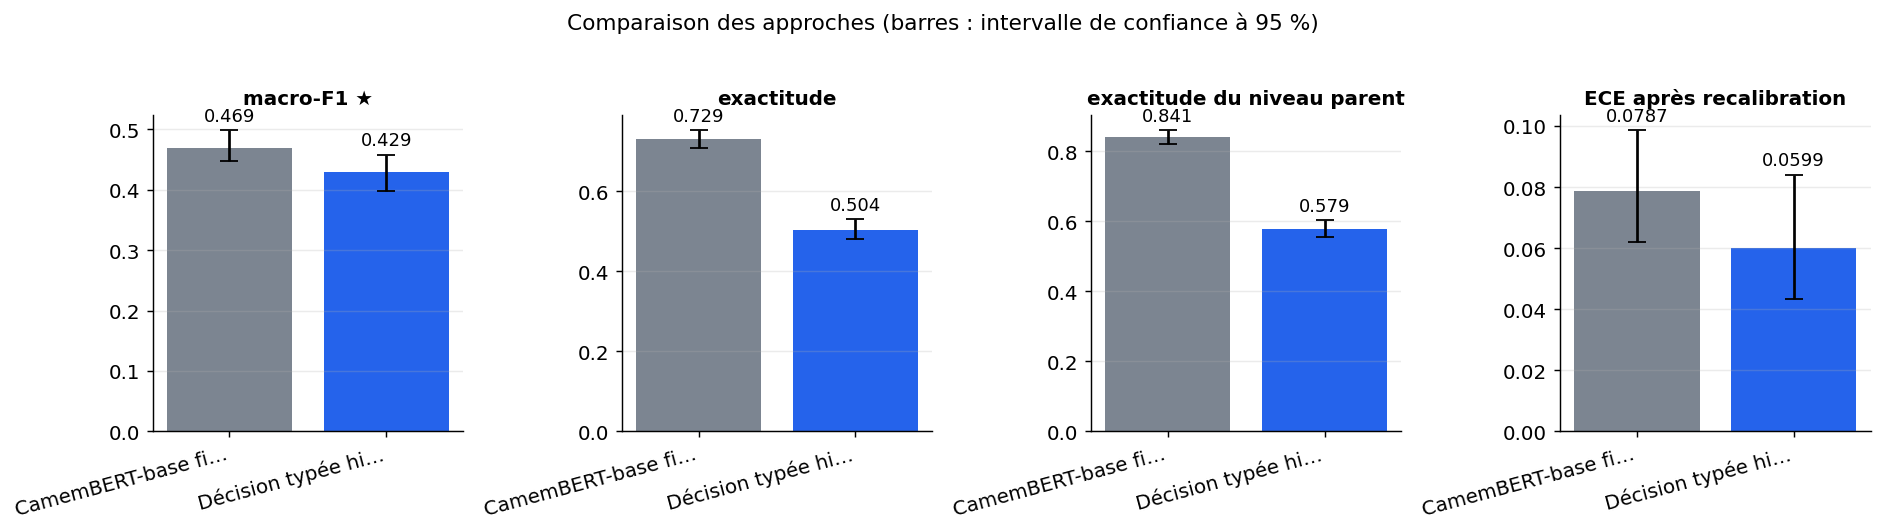

*Figure — Macro-F1, exactitude (classe fine et parente) et ECE après recalibration, avec intervalles de confiance à 95 %. Plus haut = mieux, sauf pour l'ECE (plus bas = mieux).*

In [39]:
METRIC_LABELS = {
    "macro_f1": "macro-F1", "accuracy": "exactitude", "parent_accuracy": "exactitude du niveau parent",
    "parent_child_consistency": "cohérence parent-enfant", "expected_calibration_error": "ECE après recalibration",
    "ece_uncalibrated": "ECE avant recalibration", "brier_score": "score de Brier",
    "option_order_agreement": "accord sous permutation des options", "latency_ms_per_example": "latence p50 (ms)",
}
llm_source = LLM_ID if PHASE == "public" else "LLM du service interne"
logprob_note = "" if PHASE == "public" else (
    " ; log-probabilités " + ("disponibles" if SERVICE_STATE["logprobs"] else "indisponibles (réponse écrite seule)"))
results = save_results({
    "primary_metric": "macro_f1", "direction": "max", "metric_labels": METRIC_LABELS,
    "dataset": {**DATASET_INFO, "n_examples": int(len(test_df))},
    "approaches": [
        {"name": "CamemBERT-base fine-tuné", "role": "reference", "metrics": reference_metrics,
         "ci95": reference_ci, "latency_ms": reference_latency,
         "notes": f"{EPOCHS} époque(s) sur {len(train_df)} textes ; température {reference_temperature:.2f} "
                  "ajustée sur la validation ; parent obtenu par somme des probabilités des enfants."},
        {"name": "Décision typée hiérarchique par LLM", "role": "new", "metrics": llm_metrics,
         "ci95": llm_ci, "latency_ms": llm_latency,
         "notes": f"Zéro-shot, {llm_source} ; température {llm_temperature:.2f} ; sorties illisibles "
                  f"{llm_outputs['invalid_rate']:.1%} ; accord d'ordre sur {len(permutation_texts)} textes × "
                  f"{N_PERMUTATIONS} permutations ; cohérence parent-enfant garantie par construction{logprob_note}."},
    ],
})
table = results_table(results)
if table is not None:
    display(table)
plot_comparison(results, metrics=["macro_f1", "accuracy", "parent_accuracy", "expected_calibration_error"],
                caption="Macro-F1, exactitude (classe fine et parente) et ECE après recalibration, avec intervalles "
                        "de confiance à 95 %. Plus haut = mieux, sauf pour l'ECE (plus bas = mieux).")

## 6. Analyse des résultats

### Les probabilités disent-elles vrai ? Diagramme de fiabilité

Pour chaque bac de confiance, on trace le **taux de bonnes réponses observé** en fonction de la **confiance annoncée**. Une courbe sous la diagonale signale de la **surconfiance**, le défaut central relevé par l'audit. Les tirets montrent les probabilités brutes, le trait plein les probabilités après température.

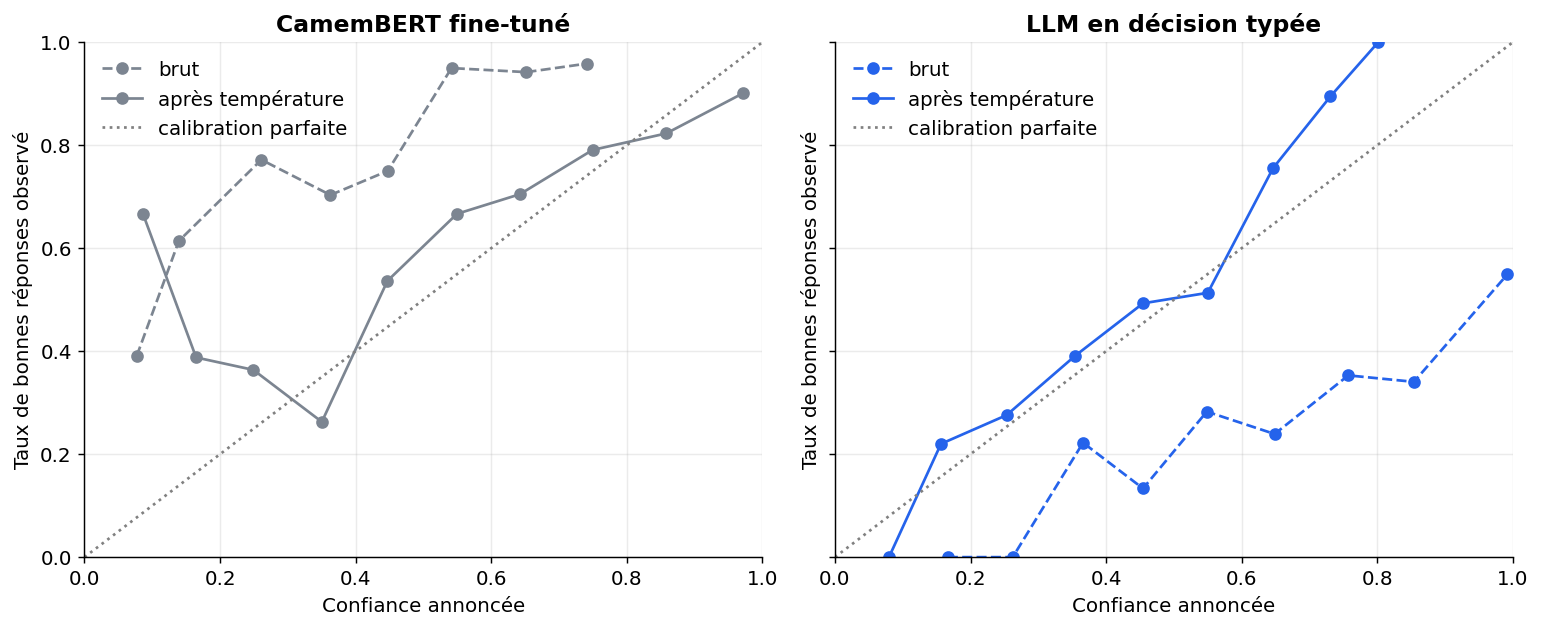

*Figure — Diagramme de fiabilité de chaque approche : un point sous la diagonale signale une confiance trop élevée. Tirets : probabilités brutes ; trait plein : après recalibration par température.*

In [40]:
APPROACHES = [("CamemBERT fine-tuné", reference_outputs, COLORS["reference"]),
              ("LLM en décision typée", llm_outputs, COLORS["new"])]


def reliability_curve(correct: np.ndarray, confidence: np.ndarray) -> np.ndarray:
    """Confiance moyenne et taux de réussite de chaque bac non vide (tableau à deux colonnes)."""
    bins = calibration_bins(confidence)
    return np.array([(confidence[bins == b].mean(), correct[bins == b].mean())
                     for b in range(ECE_BINS) if np.any(bins == b)])


fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for axis, (name, outputs, color) in zip(axes, APPROACHES):
    correct = (outputs["pred_labels"] == test_df["label"].to_numpy()).astype(float)
    for key, style, label in (("probs_raw", "--", "brut"), ("probs", "-", "après température")):
        curve = reliability_curve(correct, prediction_confidence(outputs[key], outputs["pred_labels"]))
        axis.plot(curve[:, 0], curve[:, 1], style, marker="o", color=color, label=label)
    axis.plot([0, 1], [0, 1], ":", color="grey", label="calibration parfaite")
    axis.set(title=name, xlabel="Confiance annoncée", ylabel="Taux de bonnes réponses observé",
             xlim=(0, 1), ylim=(0, 1))
    axis.legend()
fig.tight_layout()
save_figure(fig, "reliability",
            "Diagramme de fiabilité de chaque approche : un point sous la diagonale signale une confiance "
            "trop élevée. Tirets : probabilités brutes ; trait plein : après recalibration par température.")

### Où se situent les écarts ? F1 par catégorie parente

On calcule le F1 de chaque classe fine, puis sa moyenne au sein de chaque catégorie parente. Une catégorie où le LLM décroche nettement signale souvent des **noms d'options ambigus**. Elle peut aussi signaler des intentions que seuls des exemples étiquetés permettent de séparer.

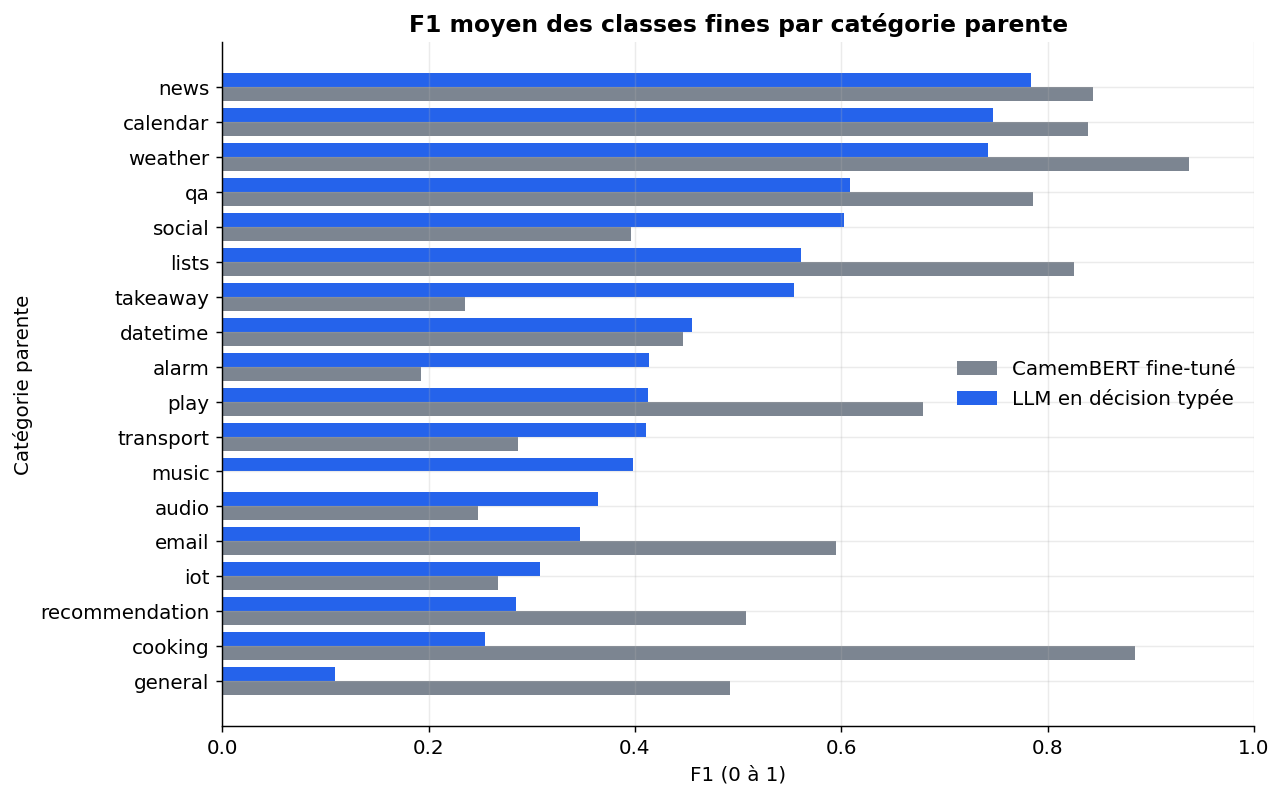

*Figure — F1 moyen des classes fines, par catégorie parente et par approche. Les catégories du bas sont celles où le LLM en décision typée est le plus faible.*

In [41]:
def f1_by_parent(pred_labels: np.ndarray) -> pd.Series:
    """F1 moyen des classes fines présentes dans le test, regroupées par catégorie parente."""
    present = [label for label in classes if label in set(test_df["label"])]
    scores = f1_score(test_df["label"], pred_labels, labels=present, average=None, zero_division=0)
    per_class = pd.Series(scores, index=present)
    return per_class.groupby(per_class.index.map(taxonomy["parent_of"])).mean()


parent_scores = pd.DataFrame({name: f1_by_parent(outputs["pred_labels"]) for name, outputs, _ in APPROACHES})
parent_scores = parent_scores.sort_values(APPROACHES[1][0])
positions = np.arange(len(parent_scores))
fig, axis = plt.subplots(figsize=(10, max(4, 0.35 * len(parent_scores))))
for offset, (name, _, color) in zip((-0.2, 0.2), APPROACHES):
    axis.barh(positions + offset, parent_scores[name], height=0.4, color=color, label=name)
axis.set_yticks(positions, parent_scores.index)
axis.set(title="F1 moyen des classes fines par catégorie parente", xlabel="F1 (0 à 1)",
         ylabel="Catégorie parente", xlim=(0, 1))
axis.legend()
fig.tight_layout()
save_figure(fig, "f1_by_parent",
            "F1 moyen des classes fines, par catégorie parente et par approche. Les catégories du bas sont "
            "celles où le LLM en décision typée est le plus faible.")

### Mauvaise parente ou mauvais enfant ?

On classe chaque décision en trois cas, à partir de la **parente de la classe prédite** :
- bonne intention ;
- bonne parente mais mauvaise intention ;
- mauvaise parente.

Une erreur au premier niveau du LLM est **irrattrapable** : le second niveau ne voit que les enfants de la parente retenue.

In [42]:
def error_breakdown(outputs: dict) -> dict:
    """Parts des décisions exactes, des erreurs d'enfant et des erreurs de parente."""
    true_labels = test_df["label"].to_numpy()
    pred = outputs["pred_labels"]
    predicted_parent = np.array([taxonomy["parent_of"].get(label, INVALID) for label in pred])
    right_parent = predicted_parent == test_df["parent"].to_numpy()
    return {"bonne intention": np.mean(pred == true_labels),
            "bonne parente, mauvaise intention": np.mean(right_parent & (pred != true_labels)),
            "mauvaise parente": np.mean(~right_parent),
            "sorties illisibles": outputs["invalid_rate"]}


breakdown = pd.DataFrame({name: error_breakdown(outputs) for name, outputs, _ in APPROACHES})
display((100 * breakdown).round(1).rename_axis("part des décisions de test (%)"))

,CamemBERT fine-tuné,LLM en décision typée
part des décisions de test (%),,
bonne intention,72.9,50.4
"bonne parente, mauvaise intention",14.0,7.5
mauvaise parente,13.1,42.1
sorties illisibles,0.0,0.0


### L'hypothèse tient-elle ?

On confronte les mesures aux trois critères de l'hypothèse. À l'échelle réduite, les deux modèles sont bridés : la référence est sous-entraînée et le LLM est un substitut plus petit. Le verdict n'y vaut que comme **vérification du code**.

In [43]:
gap_points = 100 * (reference_metrics["macro_f1"] - llm_metrics["macro_f1"])
calibrated_ece = llm_metrics["expected_calibration_error"]
order_agreement = llm_metrics["option_order_agreement"]
checks = pd.DataFrame([
    {"critère": "Écart de macro-F1 avec CamemBERT < 10 points", "mesure": f"{gap_points:.1f} points",
     "atteint": bool(gap_points < 10)},
    {"critère": "ECE du LLM après recalibration < 0,10", "mesure": f"{calibrated_ece:.3f}",
     "atteint": bool(calibrated_ece < 0.10)},
    {"critère": "Décisions identiques sous permutation ≥ 95 %", "mesure": f"{order_agreement:.1%}",
     "atteint": bool(order_agreement >= 0.95)},
])
display(checks.set_index("critère"))

,mesure,atteint
critère,,
Écart de macro-F1 avec CamemBERT < 10 points,4.0 points,True
"ECE du LLM après recalibration < 0,10",0.060,True
Décisions identiques sous permutation ≥ 95 %,49.0%,False


### Exemples d'erreurs (phase publique seulement)

On montre les erreurs du LLM **les plus confiantes**. Ce sont les plus coûteuses si l'on automatise les décisions à seuil de confiance. Ces textes ne sont affichés que pour le jeu public.

In [44]:
if PHASE == "public":
    errors = test_df.assign(
        llm=llm_outputs["pred_labels"],
        camembert=reference_outputs["pred_labels"],
        llm_confidence=np.round(prediction_confidence(llm_outputs["probs"], llm_outputs["pred_labels"]), 2),
    )
    errors = errors[errors["llm"] != errors["label"]].sort_values("llm_confidence", ascending=False)
    preview(errors[["text", "label", "llm", "camembert", "llm_confidence"]], n=8)

### À retenir

- **Précision** : si l'écart de macro-F1 dépasse 10 points, un classifieur entraîné reste préférable dès qu'on dispose d'exemples étiquetés, comme dans l'audit. S'il reste en deçà, le LLM zéro-shot devient une option sérieuse pour démarrer sans annotation ou pour couvrir de nouvelles classes.
- **Calibration** : si l'ECE brute du LLM est élevée et que la courbe de fiabilité passe sous la diagonale, sa confiance native est trompeuse. Il faut alors la **recalibrer sur des données étiquetées** avant de fixer un seuil d'automatisation.
- **Hiérarchie** : si les erreurs du LLM viennent surtout d'une **mauvaise parente**, explorer deux branches au premier niveau ou améliorer les libellés des catégories est la piste la plus rentable.
- **Stabilité** : un accord sous permutation inférieur à 95 % signale un biais de position. On peut alors moyenner les probabilités sur plusieurs ordres, ce qui multiplie le coût.
- **Portée** : à l'échelle réduite, les chiffres valident le code, pas la conclusion. Seule l'échelle complète puis les données internes, avec leur taxonomie réelle, permettent de trancher.

## 7. Bilan

> **Verdict** (confiance moyenne). À l'échelle complète (phase publique, 1 500 énoncés de test, GPU), le LLM zéro-shot de 3 Md reste à 4 points de macro-F1 de CamemBERT (0,43 contre 0,47), mais l'exactitude chute de 72,9 % à 50,4 % et la parente est fausse dans 42 % des cas, contre 13 %. L'ECE passe sous 0,10 après recalibration (0,06), au prix de probabilités très aplaties (Brier 0,70 contre 0,40). L'accord sous permutation des options n'est que de 49 %, très loin des 95 % visés. La référence est probablement sous-entraînée, ce qui flatte le LLM. Un classifieur entraîné reste donc préférable dès qu'il existe des étiquettes, et l'approche par LLM n'est pas prête sans correction du biais d'ordre.

*Échelle complète : 1500 exemples de test de `mteb/amazon_massive_intent` (GPU T4 (Google Colab), 13 min). La mécanique avait d'abord été validée à l'échelle réduite (200 exemples, CPU).*

| Approche | macro-F1 ★ ↑ | exactitude ↑ | exactitude du niveau parent ↑ | cohérence parent-enfant ↑ | ECE après recalibration ↓ | ECE avant recalibration ↓ | score de Brier ↓ | accord sous permutation des options ↑ | latence p50 (ms) ↓ | Latence médiane (ms) ↓ |
|---|---|---|---|---|---|---|---|---|---|---|
| CamemBERT-base fine-tuné (référence) | **0,469 [0,447 ; 0,499]** | **0,729 [0,707 ; 0,752]** | **0,841 [0,821 ; 0,86]** | 0,941 [0,928 ; 0,953] | 0,0787 [0,0619 ; 0,0986] | **0,381 [0,359 ; 0,402]** | **0,397 [0,37 ; 0,426]** | — | **8,4** | 8,4 |
| Décision typée hiérarchique par LLM (nouvelle approche) | 0,429 [0,398 ; 0,458] | 0,504 [0,48 ; 0,53] | 0,579 [0,556 ; 0,603] | — | **0,0599 [0,0433 ; 0,0841]** | 0,436 [0,411 ; 0,459] | 0,704 [0,679 ; 0,726] | 0,49 [0,448 ; 0,532] | 137 | 137 |

★ métrique principale · ↑ plus haut = meilleur · ↓ plus bas = meilleur · entre crochets : intervalle de confiance à 95 % (bootstrap) · en gras : la meilleure valeur.

**Réserves**

- Ne pas lire « à 4 points de CamemBERT » comme une quasi-équivalence. Sur le routage effectif, le LLM se trompe de catégorie parente dans plus de 4 cas sur 10, contre un peu plus de 1 sur 10 pour CamemBERT.
- CamemBERT est ici sous-exploité, et l'écart réel avec le LLM est probablement plus grand que celui mesuré, en particulier sur le macro-F1. Les 4 points sont une borne basse de l'avantage d'un classifieur entraîné.
- La décision du LLM dépend fortement de l'ordre de présentation des options. Une moitié des décisions change quand on mélange cet ordre, donc les chiffres de précision du LLM sont fragiles et ne sont pas exploitables en production telle quelle.
- Le passage de l'ECE sous 0,10 ne signifie pas que la confiance du LLM est utile pour décider seul ou escalader. Après recalibration, ses probabilités sont proches de l'indécision, et son Brier est bien moins bon que celui de CamemBERT.

**Limites**

- MASSIVE contient des énoncés courts d'assistant virtuel répartis en 60 classes peu déséquilibrées. Les messages réels sont plus longs et plus nombreux en classes (environ 300) : les écarts mesurés ici ne se transposent pas tels quels.
- Le décodage hiérarchique n'explore qu'une branche. Une erreur au premier niveau est irrattrapable, et les probabilités des branches non explorées sont réparties uniformément, ce qui approxime la calibration et le score de Brier.
- Les noms d'options proviennent des étiquettes (en anglais pour MASSIVE) et ne sont accompagnés d'aucune description. Des libellés plus explicites pourraient changer nettement le résultat du LLM.
- Une seule température est partagée par les deux niveaux, et la recalibration exige des exemples étiquetés de validation. Le LLM n'est donc pas entièrement « sans annotation » si l'on veut des probabilités fiables.
- Si le service interne ne fournit pas les log-probabilités, l'approche se replie sur la réponse écrite. Les probabilités deviennent alors grossières, et la calibration comme l'ECE perdent leur sens.

**Échelle réduite : ce qui diffère de l'échelle complète**

- À l'échelle réduite, Qwen2.5-0.5B-Instruct (même famille) remplace Qwen2.5-3B-Instruct pour tenir sur CPU. CamemBERT est fine-tuné sur 300 énoncés pendant 1 époque, avec des lots de 16. La validation compte 100 énoncés, le test 200, le test de permutation 40 textes et la latence est mesurée sur 20 textes. La référence y est donc fortement sous-entraînée et le LLM plus faible : ces chiffres valident le code, pas la conclusion.

**Améliorations possibles**

- Les intervalles de confiance du macro-F1 sont larges (environ ±5 points). Les différences de quelques points entre approches sont difficiles à distinguer du bruit.
- Les résultats ne sont pas directement comparables aux chiffres de l'audit (modération, anglais, modèle commercial). Seul le sens qualitatif est concordant : un classifieur entraîné reste devant, et la confiance brute est mauvaise.

**Et ensuite ?** Rejouer le même protocole sur vos données : `PHASE = "private"`, `SCALE = "full"`, après avoir préparé le jeu et la configuration décrits dans le README (section « Sur vos données »).